In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [3]:
df = pd.read_csv('../data/raw/penguins_size.csv')
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## Типы признаков

Числовые (непрерывные): culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g
Категориальные: species, island, sex

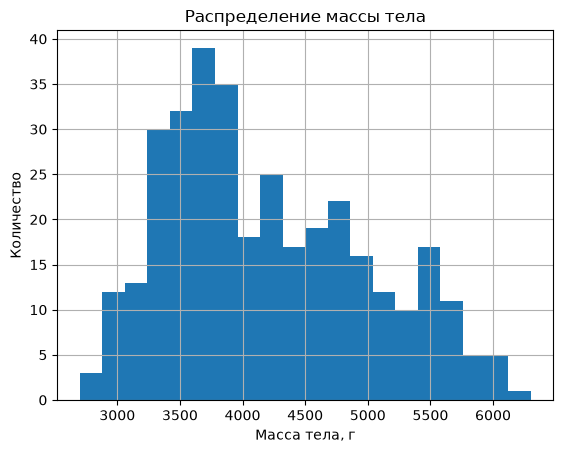

In [4]:
df['body_mass_g'].hist(bins=20)
plt.xlabel('Масса тела, г')
plt.ylabel('Количество')
plt.title('Распределение массы тела')
plt.show()

## График массы тела
Видно четкое среднее значение для всех видов в общем

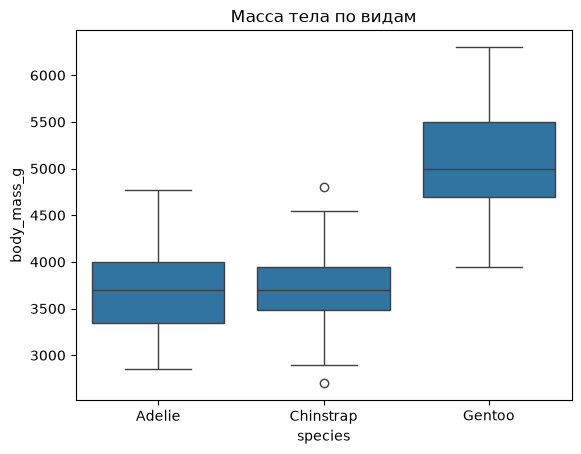

In [5]:
sns.boxplot(data=df, x='species', y='body_mass_g')
plt.title('Масса тела по видам')
plt.show()

## Масса по видам
Здесь же есть разделение по видам и для каждого вида есть среднее значение в виде черной линии, а так же максимальные и минимальные значения.


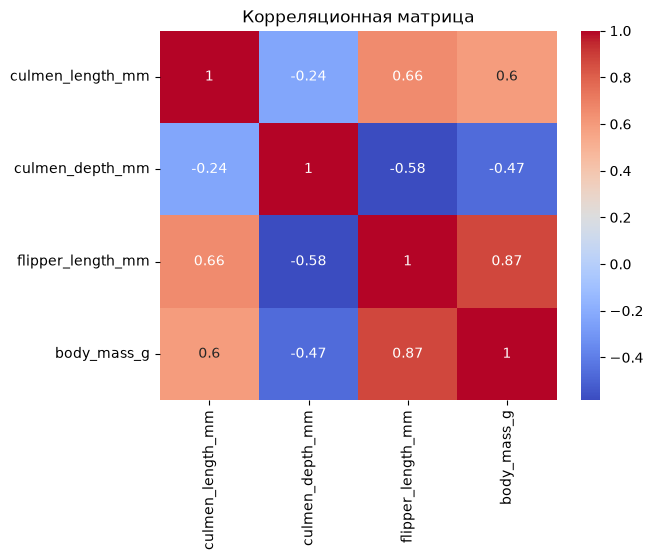

In [6]:
numeric_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
corr = df[numeric_cols].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Корреляционная матрица')
plt.show()

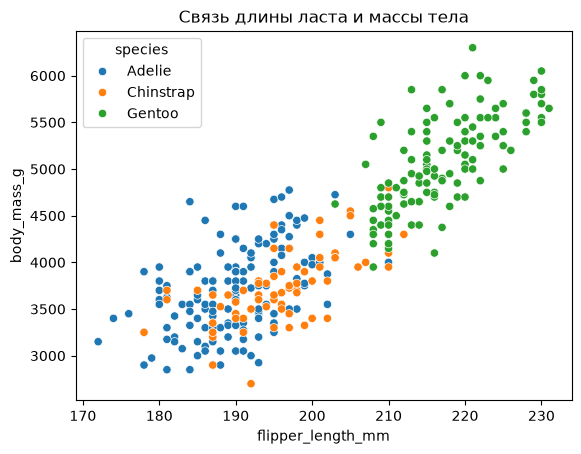

In [7]:
sns.scatterplot(data=df, x='flipper_length_mm', y='body_mass_g', hue='species')
plt.title('Связь длины ласта и массы тела')
plt.show()

## Гипотезы

In [8]:
groups = [df[df['species']==sp]['body_mass_g'].dropna() for sp in df['species'].unique()]
stat, p = stats.f_oneway(*groups)
print(f'ANOVA: stat={stat:.2f}, p={p:.5f}')

ANOVA: stat=343.63, p=0.00000


H1 (ANOVA, вид vs масса): p=0.00000 — практически нулевая вероятность, что различия в массе тела между видами случайны. Значит, species — сильный предиктор body_mass_g.

In [9]:
clean = df[['flipper_length_mm', 'body_mass_g']].dropna()
r, p = stats.pearsonr(clean['flipper_length_mm'], clean['body_mass_g'])
print(f'Pearson r={r:.2f}, p={p:.5f}')

Pearson r=0.87, p=0.00000


H1 (ANOVA, вид vs масса): p=0.00000 — практически нулевая вероятность, что различия в массе тела между видами случайны. Значит, species — сильный предиктор body_mass_g.

In [10]:
contingency = pd.crosstab(df['island'], df['species'])
chi2, p, dof, expected = stats.chi2_contingency(contingency)
print(f'chi2={chi2:.2f}, p={p:.5f}')
contingency

chi2=299.55, p=0.00000


species,Adelie,Chinstrap,Gentoo
island,,,
Biscoe,44,0,124
Dream,56,68,0
Torgersen,52,0,0


Из такого количества нулей в таблице можно сделать вывод, что есть некоторая data-leakage. У модели будет очень легкий в использовании чит, ибо по названию острова она почти гарантированно сможет угадывать вид пингвинов. В этом и заключается "грязь" взятого мной датасета